# EXP001_Baseline · Nhận diện biểu cảm trên FER2013

Thí nghiệm đo hiệu quả của CNN huấn luyện từ đầu trên ảnh xám 48 × 48. Chạy các ô theo thứ tự để xem lại kết quả đã lưu. Đặt `TRAIN_AGAIN = True` để huấn luyện một lượt mới bằng cấu hình YAML.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

project = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "BTL02")
               if (p / "configs/baseline.yaml").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from models.baseline_cnn import BaselineCNN
from train import run_experiment

## Kiến trúc

Mỗi phép tích chập có kernel 3 × 3, stride 1 và padding 1. ReLU giữ nguyên kích thước tensor. Max pooling 2 × 2 giảm một nửa chiều cao và chiều rộng.

| Lớp | Kích thước đầu ra |
|---|---|
| Ảnh đầu vào | N × 1 × 48 × 48 |
| Conv1, ReLU | N × 32 × 48 × 48 |
| MaxPool1 | N × 32 × 24 × 24 |
| Conv2, ReLU | N × 64 × 24 × 24 |
| MaxPool2 | N × 64 × 12 × 12 |
| Conv3, ReLU | N × 128 × 12 × 12 |
| MaxPool3 | N × 128 × 6 × 6 |
| Flatten | N × 4608 |
| Linear, ReLU | N × 128 |
| Linear | N × 7 |

Bảy giá trị đầu ra là logits. `CrossEntropyLoss` nhận trực tiếp logits và nhãn `torch.long` từ 0 đến 6.

In [2]:
model = BaselineCNN()
print(model)
print(f"Số tham số có thể huấn luyện: {sum(p.numel() for p in model.parameters()):,}")

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4608, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=7, bias=True)
  )
)
Số tham số có thể huấn luyện: 683,527


## Dữ liệu và huấn luyện

- **Training và validation.** Dùng đúng phép chia trong `train.ipynb` trên 28.709 dòng của `train.csv`: lấy 20% cho validation, phân tầng theo nhãn, seed chia tập cố định 42. Pixel được chia cho 255. Baseline dùng ảnh nguyên bản ở cả ba tập.
- **Cấu hình.** Adam, learning rate 0,001, batch 64, 30 epoch, seed huấn luyện 42. Mỗi lượt lưu checkpoint có validation loss nhỏ nhất và lịch sử theo epoch.
- **Test.** Ảnh lấy từ `test.csv`. Khi tệp thiếu nhãn, module dữ liệu kiểm tra từng chuỗi pixel theo đúng thứ tự so với 7.178 ảnh PublicTest và PrivateTest trong `fer2013.csv` rồi mới gán nhãn. Chỉ đánh giá test sau khi chọn checkpoint.
- **Kiểm thử.** Từ thư mục BTL02, chạy `python train.py --smoke` để kiểm tra forward, loss, gradient trên batch thật và chạy một epoch train/validation. Lệnh `python train.py` chạy trọn thí nghiệm; chỉnh siêu tham số trong `configs/baseline.yaml`.

In [3]:
TRAIN_AGAIN = False
run = project / "results/EXP001_Baseline/20261119_210009_727860"
if TRAIN_AGAIN or not (run / "evaluation.json").is_file():
    run = run_experiment()

training = json.loads((run / "training.json").read_text(encoding="utf-8"))
history = pd.read_csv(run / "history.csv")
print(f"Thư mục: {run.name} | Thiết bị: {training['hardware']}")
print(f"Thời gian huấn luyện: {training['training_seconds']:.1f} giây")
display(history.loc[history.epoch == training["best_epoch"]])

Thư mục: 20261119_210009_727860 | Thiết bị: NVIDIA GeForce RTX 3050 Laptop GPU
Thời gian huấn luyện: 79.2 giây


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
6,7,1.074061,0.596029,1.204384,0.541623


## Diễn biến theo epoch

Đường dọc đánh dấu epoch có validation loss thấp nhất. Accuracy là tỷ lệ nhãn dự đoán đúng. Đối chiếu hai đường loss để xem mô hình bắt đầu học quá khớp từ khi nào.

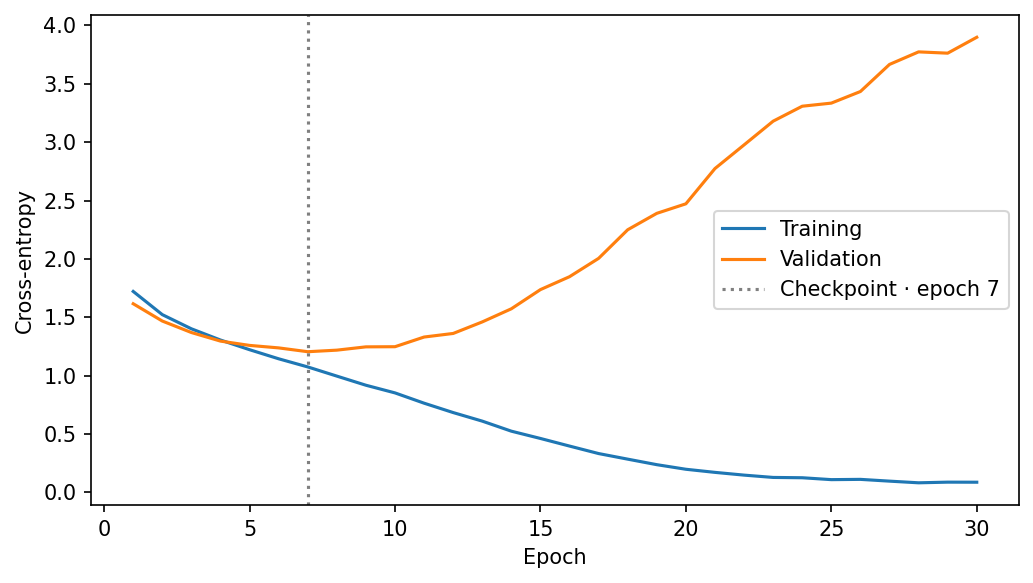

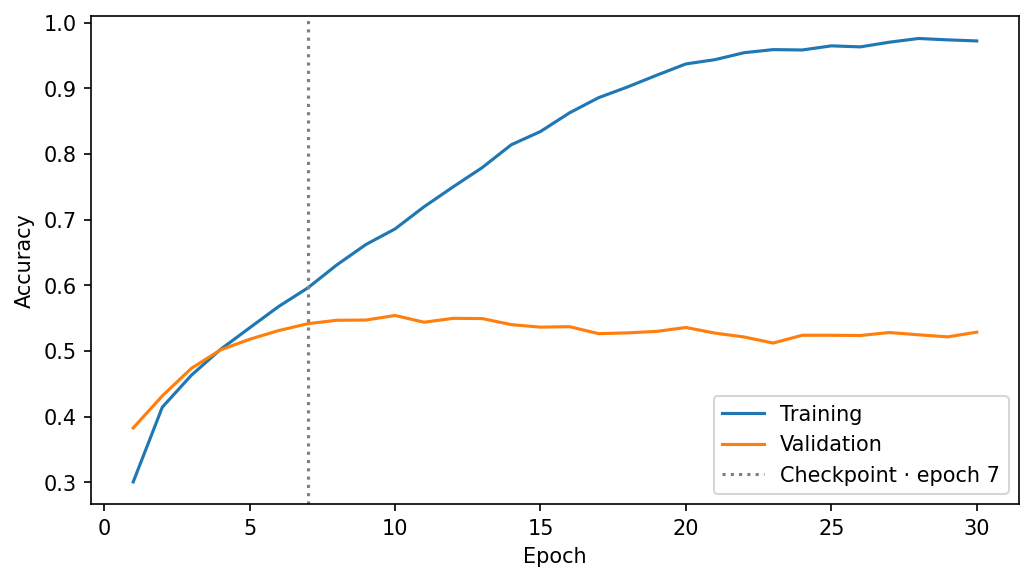

In [4]:
for name in ("loss", "accuracy"):
    display(Image(filename=str(run / f"{name}.png"), width=720))

## Đánh giá checkpoint trên tập test

Macro F1 là trung bình F1 của bảy lớp, mỗi lớp có trọng số bằng nhau. Ma trận nhầm lẫn dùng hàng cho nhãn thật và cột cho nhãn dự đoán.

Test: 7178 ảnh | Accuracy: 54.28% | Macro F1: 0.4989


,precision,recall,f1-score,support
Angry,0.4971,0.3539,0.4134,958.0
Disgust,0.6383,0.2703,0.3797,111.0
Fear,0.3846,0.2930,0.3326,1024.0
Happy,0.6981,0.7965,0.7441,1774.0
Sad,0.4073,0.4403,0.4231,1247.0
Surprise,0.6720,0.7100,0.6905,831.0
Neutral,0.4757,0.5474,0.5090,1233.0


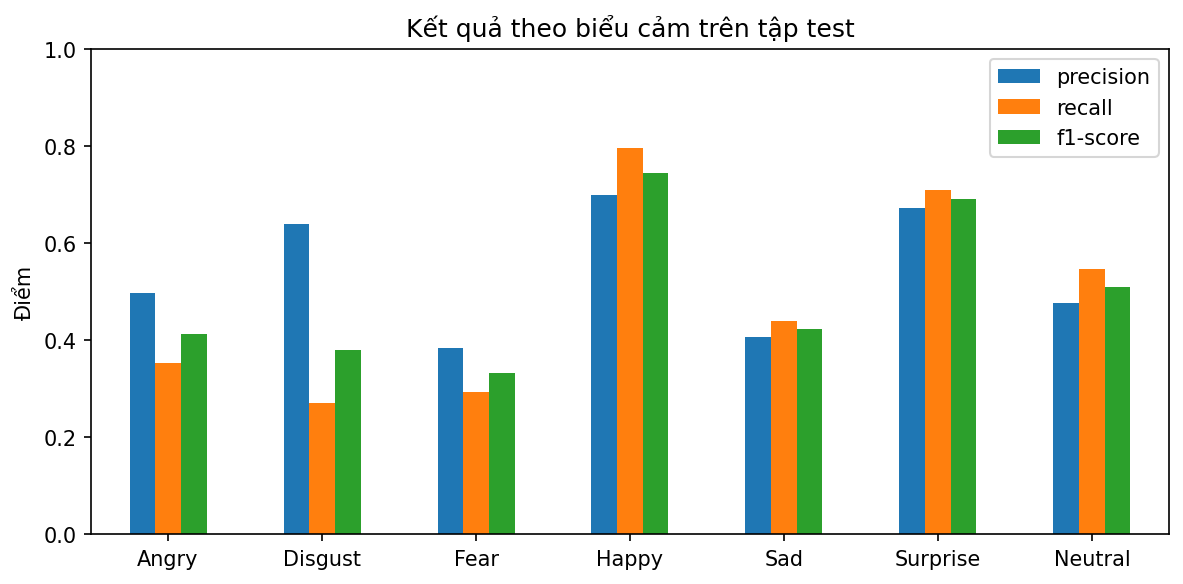

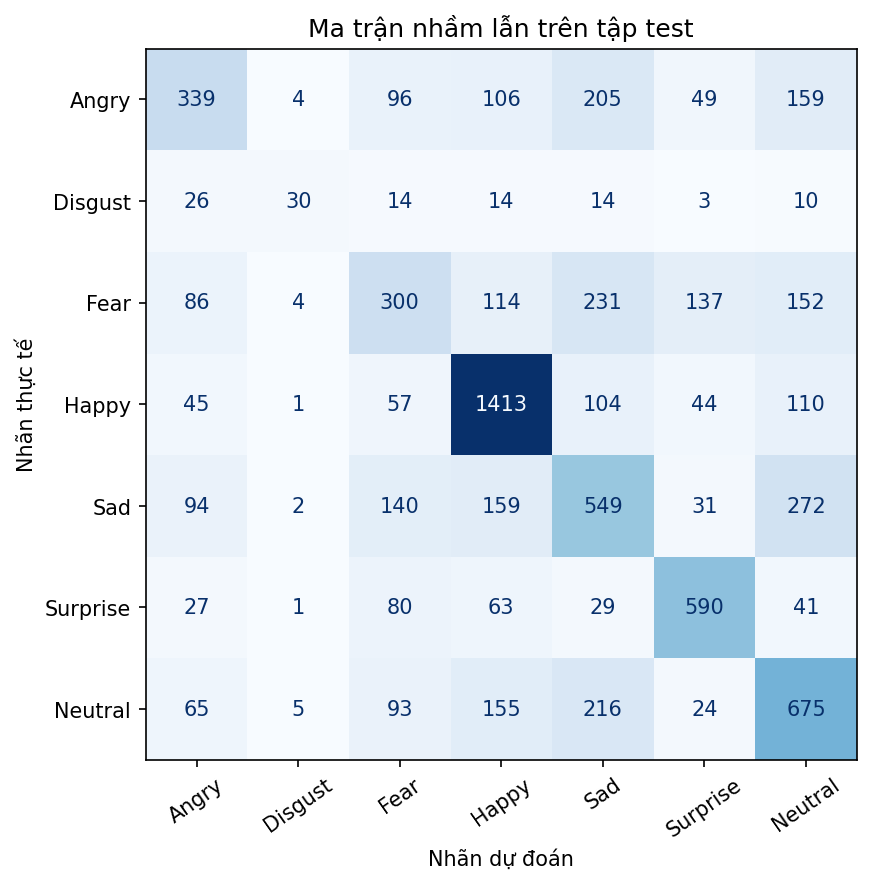

In [5]:
results = json.loads((run / "evaluation.json").read_text(encoding="utf-8"))
print(f"Test: {results['samples']} ảnh | Accuracy: {results['accuracy']:.2%} | Macro F1: {results['macro_f1']:.4f}")
display(pd.DataFrame(results["per_class"]).T.round(4))
for name in ("per_class", "confusion_matrix"):
    display(Image(filename=str(run / f"{name}.png"), width=720))

## Ảnh dự đoán và bộ lọc đã học

Hai nhóm ảnh test được lấy mẫu với seed cố định. Mỗi ảnh có nhãn thật và nhãn mô hình dự đoán. Hình cuối hiển thị từng kernel của lớp tích chập đầu tiên, dùng chung thang màu cho trọng số âm và dương.

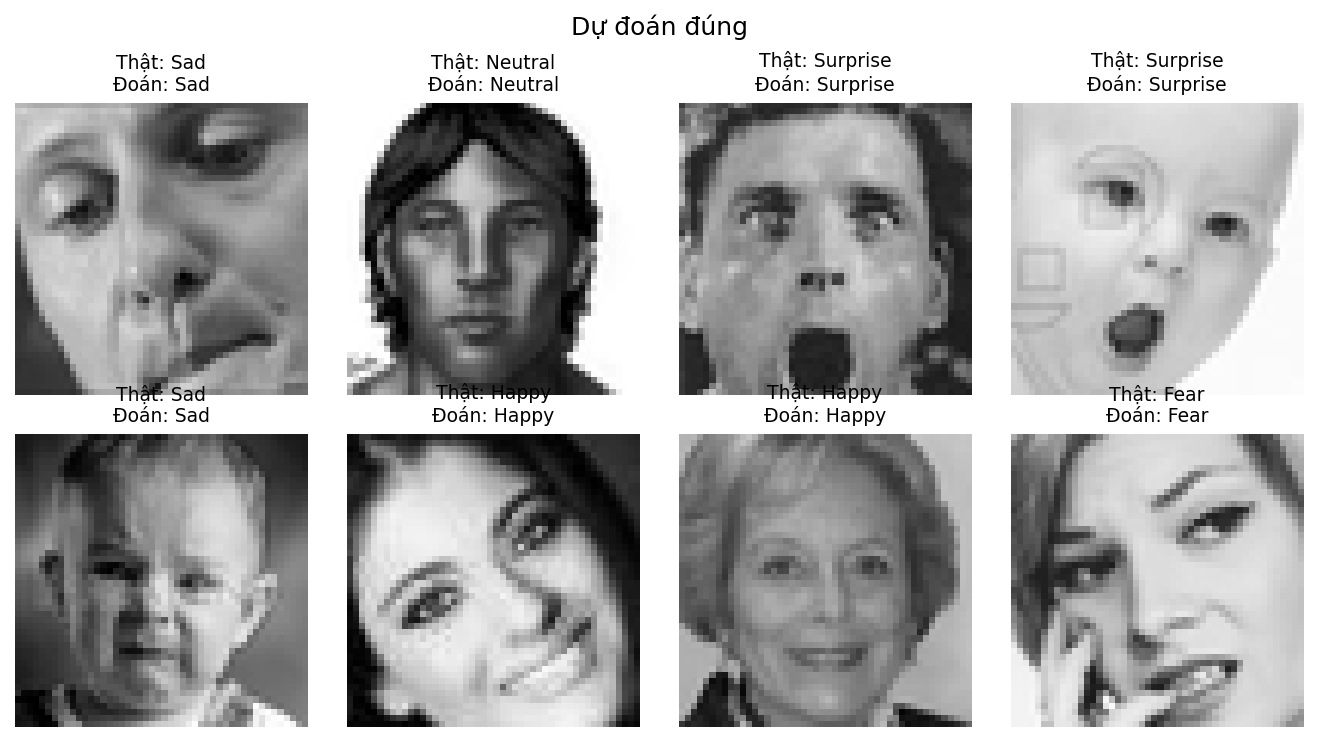

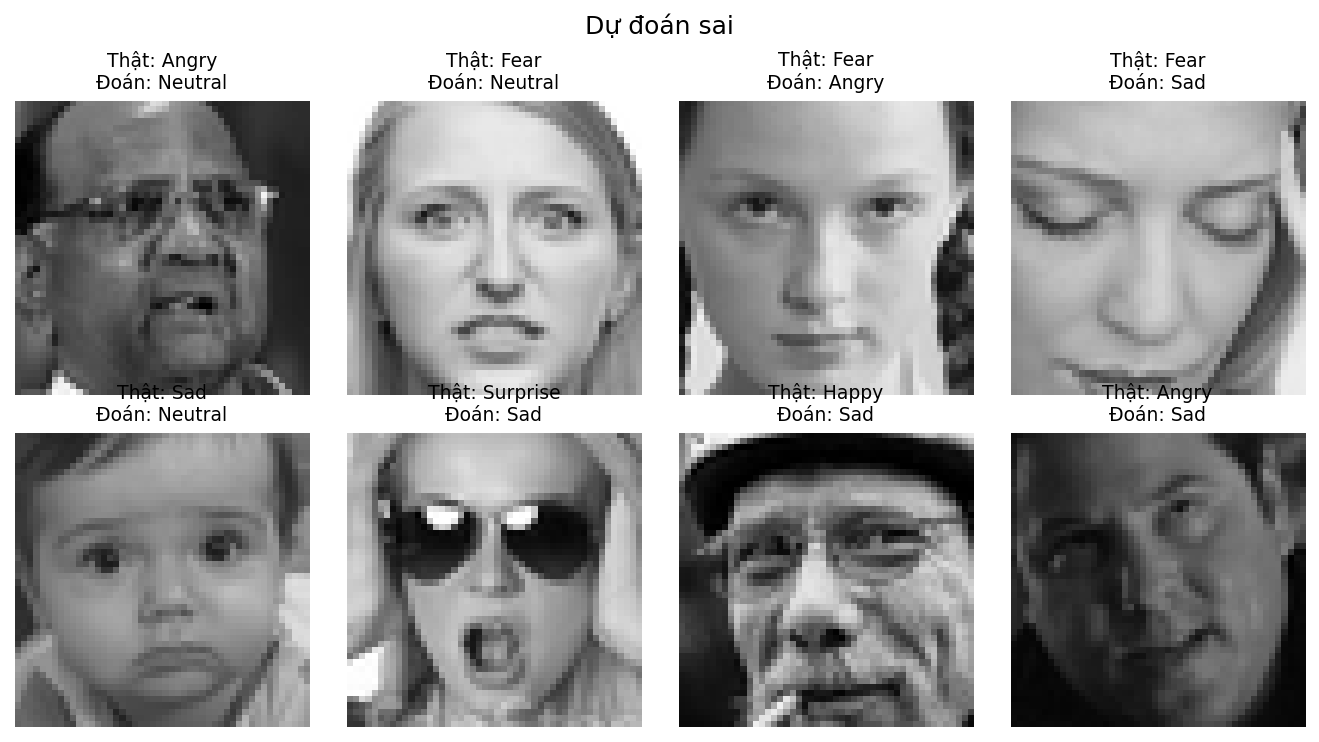

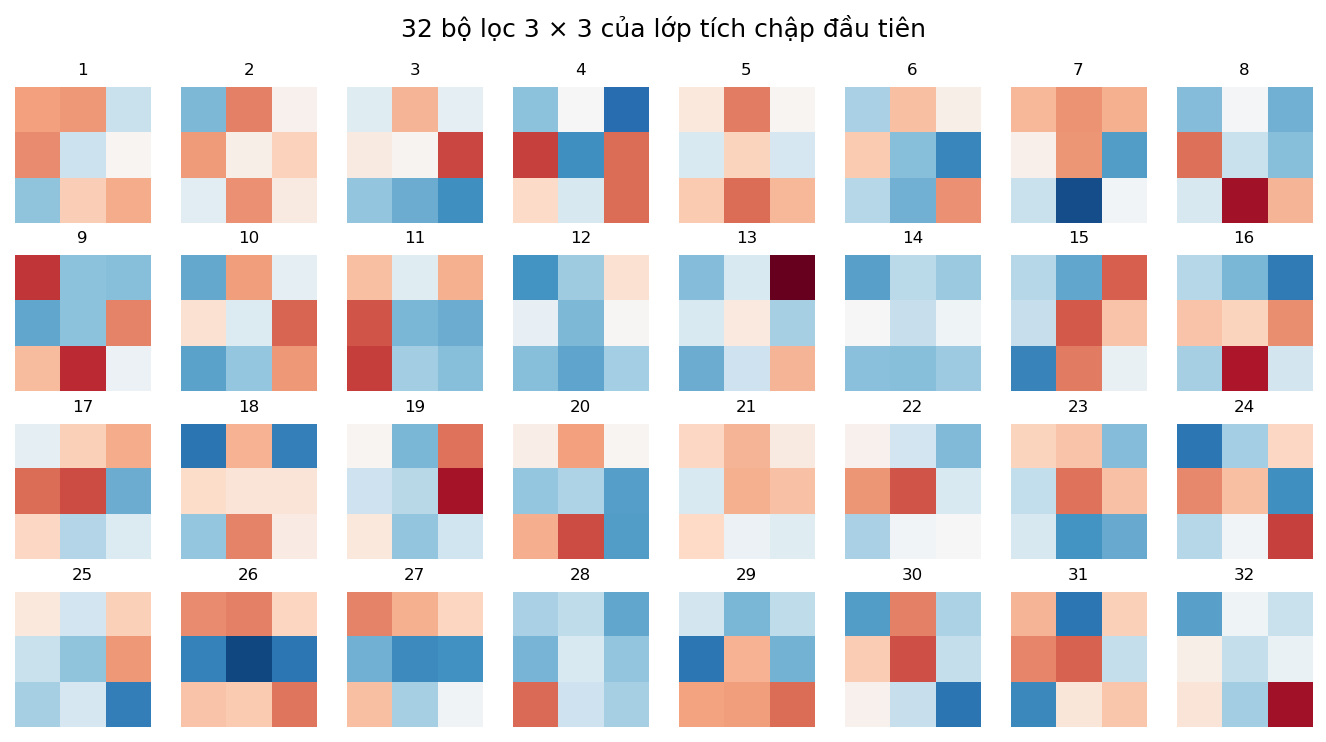

In [6]:
for name in ("correct", "incorrect", "conv1_filters"):
    display(Image(filename=str(run / f"{name}.png"), width=780))

## Dùng kết quả làm mốc

Giữ nguyên danh sách ảnh train/validation, chuẩn hóa, seed và quy tắc chọn checkpoint khi so sánh. Mỗi thí nghiệm thay đổi một yếu tố, chẳng hạn bổ sung Dropout. Dùng validation để chọn cấu hình, sau đó báo cáo chênh lệch accuracy, macro F1 và F1 từng lớp trên cùng tập test so với EXP001.